# Recruitment chatbot evaluation

This notebook displays saved, real OpenAI held-out action and Exit reports. It does not make model calls. Generate or refresh reports explicitly with the evaluation CLI using authorized redacted benchmark records.

Inputs use whole-conversation splits and exclude target recruiter replies and future turns. Stored outputs contain aggregate metrics and example IDs, never conversation text.


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "TASK.md").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "artifacts/matplotlib"))
import json
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from app.agents.backends.common import prompt_manifest
from app.config import Settings
from app.evaluation.dataset import SPLIT_NAMES, load_examples, split_examples
from app.evaluation.metrics import summarize

SPLIT = "test"
settings = Settings()
model_label = f"{settings.chat_model} + {settings.helper_model}"
print("Current configuration; saved reports retain their run-time model and prompt identities.")
print(json.dumps(settings.model_policy(), indent=2))
print(json.dumps(prompt_manifest(settings), indent=2))
print(
    f"Models: chat={settings.chat_model}, helpers={settings.helper_model}; split: {SPLIT}. This notebook reads saved reports; the evaluation CLI makes paid OpenAI API calls."
)

Current configuration; saved reports retain their run-time model and prompt identities.
{
  "main": {
    "model": "gpt-4o-mini",
    "reasoning_effort": null,
    "temperature": 0.0,
    "max_completion_tokens": 1500
  },
  "info": {
    "model": "gpt-4o-mini",
    "reasoning_effort": null,
    "temperature": 0.0,
    "max_completion_tokens": 1500
  },
  "scheduling": {
    "model": "gpt-4o-mini",
    "reasoning_effort": null,
    "temperature": 0.0,
    "max_completion_tokens": 1500
  },
  "info_decision": {
    "model": "gpt-5-nano",
    "reasoning_effort": "low",
    "temperature": null,
    "max_completion_tokens": 512
  },
  "exit": {
    "model": "gpt-5-nano",
    "reasoning_effort": "low",
    "temperature": null,
    "max_completion_tokens": 512
  },
  "profile_extraction": {
    "model": "gpt-5-nano",
    "reasoning_effort": "low",
    "temperature": null,
    "max_completion_tokens": 1500
  },
  "chat_profile": {
    "model": "gpt-4o-mini",
    "reasoning_effort": null,
    

## 1. Read the PostgreSQL benchmark and stored conversation splits

There are 15 conversations, not 59 independent conversations. Turns from one conversation stay together. Opening recruiter messages are reported separately from candidate-response decisions. The split includes opt-outs and all three candidate-response action classes in each partition.

The supplied benchmark is stored in dataset_conversations and dataset_turns under Settings.dataset_version. The database must contain that version; restore its tables from a backup on a fresh database. Live conversation exports stay separate from this verified dataset.

In [2]:
examples = load_examples(settings)
manifest = json.loads((ROOT / "data/processed/manifest.json").read_text())
splits = manifest["splits"]
assert not set(splits["train"]) & set(splits["test"])
assert not set(splits["validation"]) & set(splits["test"])
summary = []
for name in SPLIT_NAMES:
    subset = split_examples(examples, name)
    summary.append(
        {
            "split": name,
            "conversations": len(splits[name]),
            "recruiter_turns": len(subset),
            "openings": sum(row["is_opening"] for row in subset),
            **Counter(row["label"] for row in subset),
        }
    )
pd.DataFrame(summary).set_index("split")

,conversations,recruiter_turns,openings,continue,schedule,end
split,,,,,,
train,9,36,9,16,11,9
validation,3,12,3,5,4,3
test,3,11,3,4,4,3


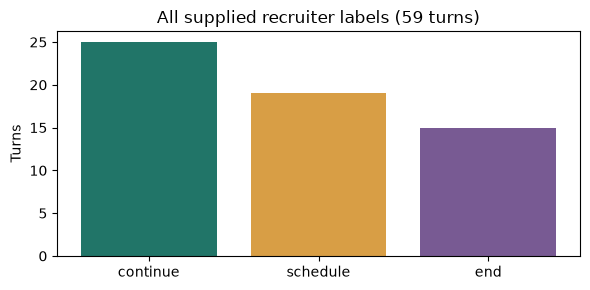

In [3]:
counts = Counter(row["label"] for row in examples)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(list(counts), list(counts.values()), color=["#217568", "#D89E45", "#785A93"])
ax.set(title="All supplied recruiter labels (59 turns)", ylabel="Turns")
plt.tight_layout()
plt.show()

## 2. Inspect exactly what becomes an input

Every message contains only `role` and `content`. The target action remains outside the input. The timestamp comes from the preceding message (or conversation start for an opening). Phone metadata is omitted and phone/email patterns are redacted.

In [4]:
example = next(
    row for row in examples if row["conversation_id"] in splits["train"] and not row["is_opening"]
)
assert all(set(message) == {"role", "content"} for message in example["history"])
print(
    {
        "conversation_id": example["conversation_id"],
        "history_messages": len(example["history"]),
        "reference_time": example["reference_time"],
        "target_excluded_from_input": True,
    }
)

{'conversation_id': 1, 'history_messages': 2, 'reference_time': '2024-04-03T15:13:19+00:00', 'target_excluded_from_input': True}


## 3. Read saved application metrics

Generate these reports explicitly before running the notebook:

```bash
python -m app.main prepare-data --base-model gpt-4.1-mini-2025-04-14
python -m app.main evaluate --task actions --split test --output artifacts/actions_test_baseline.json
python -m app.main evaluate --task exit --split test --output artifacts/exit_test_baseline.json
```

The evaluation CLI uses an empty isolated calendar for historical predictions and does not mutate the interactive calendar. Reports describe historical action-label agreement with missing calendar state; they do not establish booking correctness. Failed calls count as unsuccessful. Results also report successful-call accuracy, coverage and failure rate, with a failure column in confusion matrices when needed. The majority baseline uses training labels only. The notebook itself makes no model calls.


In [5]:
action_report = json.loads((ROOT / f"artifacts/actions_{SPLIT}_baseline.json").read_text())
model_label = f"{action_report['model']} / Exit: {action_report['exit_model']}"
assert action_report["dataset_version"] == manifest["dataset_version"]
assert action_report["dataset_sha256"] == manifest["dataset_sha256"]
majority = Counter(row["label"] for row in split_examples(examples, "train")).most_common(1)[0][0]
baseline_rows = [
    {"expected": row["label"], "predicted": majority} for row in split_examples(examples, SPLIT)
]
comparison = pd.DataFrame(
    [
        {
            "system": f"{model_label}: graph (all turns)",
            "n": action_report["all_turns"]["count"],
            "accuracy": action_report["all_turns"]["accuracy"],
            "successful_call_accuracy": action_report["all_turns"].get("successful_call_accuracy"),
            "failure_rate": action_report["all_turns"].get("failure_rate"),
        },
        {
            "system": f"{model_label}: graph (candidate responses)",
            "n": action_report["candidate_responses"]["count"],
            "accuracy": action_report["candidate_responses"]["accuracy"],
            "successful_call_accuracy": action_report["candidate_responses"].get(
                "successful_call_accuracy"
            ),
            "failure_rate": action_report["candidate_responses"].get("failure_rate"),
        },
        {
            "system": f"Training majority: {majority}",
            "n": len(baseline_rows),
            "accuracy": summarize(baseline_rows)["accuracy"],
        },
    ]
)
comparison

,system,n,accuracy,successful_call_accuracy,failure_rate
0,gpt-4o-mini / Exit: gpt-5-nano: graph (all turns),11,0.545455,0.545455,0.0
1,gpt-4o-mini / Exit: gpt-5-nano: graph (candida...,8,0.375000,0.375000,0.0
2,Training majority: continue,11,0.363636,NaN,NaN


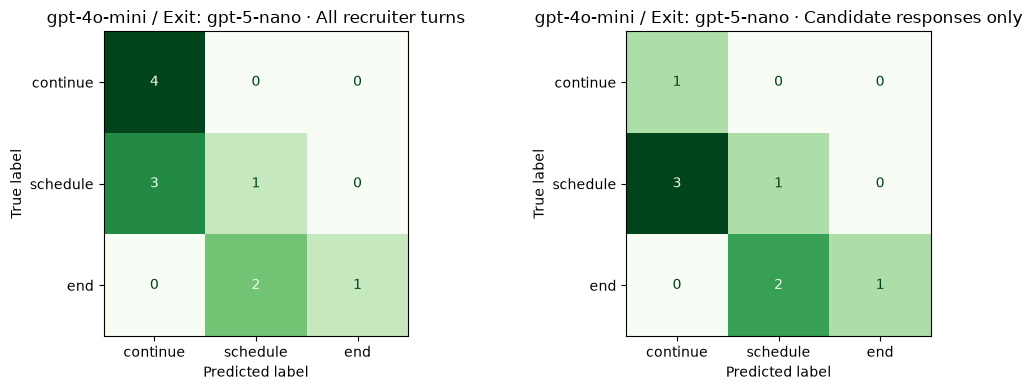

,precision,recall,f1-score,support
continue,0.571429,1.000000,0.727273,4.000000
schedule,0.333333,0.250000,0.285714,4.000000
end,1.000000,0.333333,0.500000,3.000000
accuracy,0.545455,0.545455,0.545455,0.545455
macro avg,0.634921,0.527778,0.504329,11.000000
weighted avg,0.601732,0.545455,0.504723,11.000000


In [6]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title in zip(
    axes,
    ["all_turns", "candidate_responses"],
    ["All recruiter turns", "Candidate responses only"],
    strict=False,
):
    metrics = action_report[key]
    ConfusionMatrixDisplay(
        np.asarray(metrics["confusion_matrix"]), display_labels=metrics["labels"]
    ).plot(ax=ax, colorbar=False, cmap="Greens")
    ax.set_title(f"{model_label} · {title}")
plt.tight_layout()
plt.show()
pd.DataFrame(action_report["all_turns"]["classification_report"]).T

## 4. Inspect disagreements and runtime failures

Original annotations are preserved. Some gold confirmations lack verified slot IDs, or omit an unambiguous date/time. The runtime refuses unsupported bookings. Therefore label agreement and operational correctness must be interpreted separately.

Functional tests cover date interpretation, concurrent booking, retries, session isolation, grounded-source IDs, and opt-outs.

In [7]:
rows = pd.DataFrame(action_report["rows"])
errors = rows[(rows.expected != rows.predicted) | rows.error.notna()]
print("Model/tool failures:", action_report["all_turns"]["failures"])
errors[["conversation_id", "turn_id", "expected", "predicted", "error", "seconds"]]

Model/tool failures: 0


,conversation_id,turn_id,expected,predicted,error,seconds
1,9,3,schedule,continue,None,9.217
3,9,7,end,schedule,None,7.046
5,12,3,schedule,continue,None,9.938
7,12,7,end,schedule,None,4.507
9,15,3,schedule,continue,None,9.709


## 5. Evaluate the Exit Advisor independently

`end` includes disinterest and successful closure. The advisor's recommendation is measured before application booking safeguards. This is the correct comparison point for prompted versus fine-tuned Exit Advisor models.

Model: gpt-5-nano Accuracy: 1.0
Successful-call accuracy: 1.0 Failure rate: 0.0


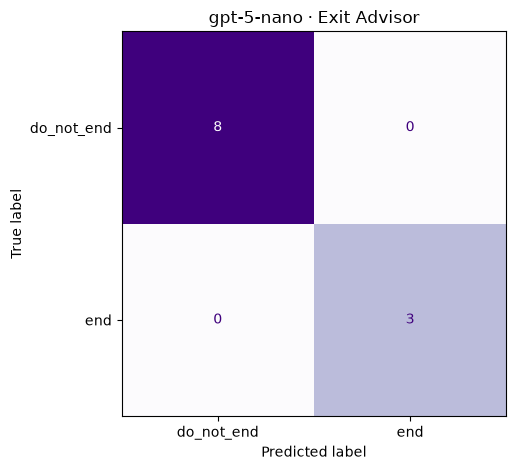

,precision,recall,f1-score,support
do_not_end,1.0,1.0,1.0,8.0
end,1.0,1.0,1.0,3.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,11.0
weighted avg,1.0,1.0,1.0,11.0


In [8]:
exit_report = json.loads((ROOT / f"artifacts/exit_{SPLIT}_baseline.json").read_text())
assert exit_report["dataset_version"] == manifest["dataset_version"]
assert exit_report["dataset_sha256"] == manifest["dataset_sha256"]
print("Model:", exit_report["exit_model"], "Accuracy:", exit_report["all_turns"]["accuracy"])
metrics = exit_report["all_turns"]
print(
    "Successful-call accuracy:",
    metrics.get("successful_call_accuracy"),
    "Failure rate:",
    metrics.get("failure_rate"),
)
ConfusionMatrixDisplay(
    np.asarray(metrics["confusion_matrix"]), display_labels=metrics["labels"]
).plot(cmap="Purples", colorbar=False)
plt.title(f"{exit_report['exit_model']} · Exit Advisor")
plt.tight_layout()
plt.show()
pd.DataFrame(metrics["classification_report"]).T

## 6. Compare a fine-tuned model when one exists

The authorized training attempt on 7 November 2026 was rejected by OpenAI with HTTP 403, `training_not_available`. Both uploaded files were deleted. No training job, model or fine-tuned metrics are claimed. An eligible account must complete training before this comparison can run.

Once a successful model ID is available, use the same held-out split:

```bash
# Settings.exit_model = "" for the prompted baseline.
python -m app.main evaluate --task exit --split test --output artifacts/exit_test_baseline.json
# Set Settings.exit_model to the returned fine-tuned ID before this command.
python -m app.main evaluate --task exit --split test --output artifacts/exit_test_finetuned.json
```

Restart the notebook kernel after configuration changes. Use validation data for selection. With only three held-out conversations, any apparent improvement is preliminary.


In [9]:
baseline_path = ROOT / f"artifacts/exit_{SPLIT}_baseline.json"
finetuned_path = ROOT / f"artifacts/exit_{SPLIT}_finetuned.json"
if baseline_path.exists() and finetuned_path.exists():
    reports = [json.loads(path.read_text()) for path in [baseline_path, finetuned_path]]
    assert all(
        report["provider"] == "openai"
        and report["split"] == SPLIT
        and report.get("dataset_version") == manifest["dataset_version"]
        and report.get("dataset_sha256") == manifest["dataset_sha256"]
        for report in reports
    ), "Compare reports from the same benchmark version and snapshot"
    display(
        pd.DataFrame(
            [
                {
                    "variant": name,
                    "model": report["exit_model"],
                    "accuracy": report["all_turns"]["accuracy"],
                }
                for name, report in zip(["baseline", "fine-tuned"], reports, strict=False)
            ]
        )
    )
else:
    print(
        "A completed fine-tuned evaluation report is not available; no fine-tuned performance is claimed."
    )

A completed fine-tuned evaluation report is not available; no fine-tuned performance is claimed.


## 7. Offline LLM answer-quality judge

Run the separate quality command explicitly with authorized, self-contained evidence packets:

```bash
python -m app.main evaluate --task quality --input tests/fixtures/quality_cases.json --output artifacts/quality_evaluation.json
```

The fixture contains independently authored fictitious examples, not human annotations. The cell below only reads a saved report; it does not call OpenAI or send the stored benchmark. The four 1–5 dimensions supplement labeled action metrics and SQL checks. Unassessable/failed ratings are excluded from means. Human agreement is reported only when reference ratings are supplied. The judge also generates some answers, so shared-model bias remains a limitation.


In [10]:
quality_path = ROOT / "artifacts/quality_evaluation.json"
if quality_path.exists():
    quality = json.loads(quality_path.read_text())
    print("Judge:", quality["judge_model"], "Rubric:", quality["rubric_version"])
    print("Usage:", quality["usage"])
    dimension_table = pd.DataFrame(quality["summary"]["dimensions"]).T
    display(dimension_table[["scored", "not_assessable", "failed", "mean"]])
else:
    print("No offline quality report is available.")

Judge: gpt-4o-mini Rubric: quality-v1
Usage: {'recorded_calls': 6, 'estimated_cost_usd': 0.00170715, 'unknown_cost_calls': 0, 'missing_trace_cases': 0, 'reported_input_tokens': 6917, 'reported_output_tokens': 1500, 'unreported_input_cases': 0, 'unreported_output_cases': 0, 'mean_model_duration_ms': 3379.798}


,scored,not_assessable,failed,mean
grounding,5,1,0,3
completeness,6,0,0,3.5
relevance_clarity,6,0,0,3.6667
followup_quality,3,3,0,3.3333


## 8. Controlled stateful workflow replay

This separate evaluation uses independently authored fictitious cases, provided job excerpts and a disposable SQL calendar. Each conversation retains offers, booking receipts and graph state across turns. Expected outcomes never enter model context. Its pass counts are operational checks, not accuracy on the historical dataset.

```bash
python -m app.main evaluate --task workflow --input tests/fixtures/workflow_cases.json --output artifacts/workflow_evaluation.json
```

The report checks mixed information/booking requests, ambiguous acceptance, exactly one confirmed booking, closure reasons and opt-outs. Follow-up generation and uploaded-profile processing are outside this replay.


In [11]:
workflow_path = ROOT / "artifacts/workflow_evaluation.json"
if workflow_path.exists():
    workflow = json.loads(workflow_path.read_text())
    print("Mode:", workflow["evaluation_mode"], "Summary:", workflow["summary"])
    display(pd.DataFrame(workflow["rows"])[["case_id", "step", "passed", "actual", "error"]])
else:
    print("No controlled workflow report is available.")

Mode: controlled_stateful_replay Summary: {'cases': 4, 'steps': 9, 'passed_steps': 9, 'passed_cases': 4, 'execution_failures': 0}


,case_id,step,passed,actual,error
0,mixed_information_and_booking,1,True,"{'action': 'schedule', 'closed': False, 'booki...",None
1,mixed_information_and_booking,2,True,"{'action': 'continue', 'closed': False, 'booki...",None
2,mixed_information_and_booking,3,True,"{'action': 'end', 'closed': True, 'bookings': ...",None
3,ambiguous_acceptance_then_confirmation,1,True,"{'action': 'schedule', 'closed': False, 'booki...",None
4,ambiguous_acceptance_then_confirmation,2,True,"{'action': 'schedule', 'closed': False, 'booki...",None
5,ambiguous_acceptance_then_confirmation,3,True,"{'action': 'end', 'closed': True, 'bookings': ...",None
6,explicit_opt_out,1,True,"{'action': 'end', 'closed': True, 'bookings': ...",None
7,information_then_disinterest,1,True,"{'action': 'continue', 'closed': False, 'booki...",None
8,information_then_disinterest,2,True,"{'action': 'end', 'closed': True, 'bookings': ...",None


## Interpretation and limitations

- Saved action and Exit reports are displayed below. The sample has only 11 held-out recruiter turns across three conversations; results are exploratory.
- There are only 15 conversations; report counts alongside percentages.
- No verified historical calendar or booking receipts were supplied. Evaluation uses an empty isolated calendar; it never creates availability.
- Source-grounded job answers require separate qualitative review with a real model.
- Fine-tuned results appear only when a completed matching report exists. Deployment status is documented separately in README.md.
